<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HancockGPT2CN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda
Clinical shape: (763, 32)
Pathology shape: (763, 18)
Merged shape: (763, 49)
Patients: 332
HPV classes (0=negative, 1=positive):
HPV_Label
0    191
1    141
Name: count, dtype: int64
Features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
N-stage source: pN_stage
Train: 215 [123  92]
Validation: 50 [29 21]
Test: 67 [39 28]
Number of clinical features: 6
Features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']

Example clinical prompt:
Q: Predict this patient's Human Papillomavirus (HPV) status using the clinical information available. This patient is 60 years old and is male. The patient is a non-smoker. The primary tumour site is Oropharynx. The primarily metastasis status is no. Pathological nodal stage is pN1. Based on these six clinical features, predict whether the patient is HPV positive or HPV negative. Answer with only Yes or No.
A:


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Training inputs: torch.Size([215, 100])
Validation inputs: torch.Size([50, 100])
Test inputs: torch.Size([67, 100])
Training features: torch.Size([215, 768])
Validation features: torch.Size([50, 768])
Test features: torch.Size([67, 768])
Epoch 1/500 | Loss: 2.4476 | Validation Accuracy: 0.4200
Epoch 2/500 | Loss: 2.8203 | Validation Accuracy: 0.4200
Epoch 3/500 | Loss: 2.4471 | Validation Accuracy: 0.4200
Epoch 4/500 | Loss: 2.0705 | Validation Accuracy: 0.4200
Epoch 5/500 | Loss: 2.6341 | Validation Accuracy: 0.4200
Epoch 6/500 | Loss: 2.6358 | Validation Accuracy: 0.4200
Epoch 7/500 | Loss: 1.3229 | Validation Accuracy: 0.4200
Epoch 8/500 | Loss: 2.4460 | Validation Accuracy: 0.4200
Epoch 9/500 | Loss: 3.0109 | Validation Accuracy: 0.4200
Epoch 10/500 | Loss: 3.0074 | Validation Accuracy: 0.4200
Epoch 11/500 | Loss: 2.0758 | Validation Accuracy: 0.4200
Epoch 12/500 | Loss: 2.0730 | Validation Accuracy: 0.4200
Epoch 13/500 | Loss: 2.4484 | Validation Accuracy: 0.4200
Epoch 14/500 | Lo

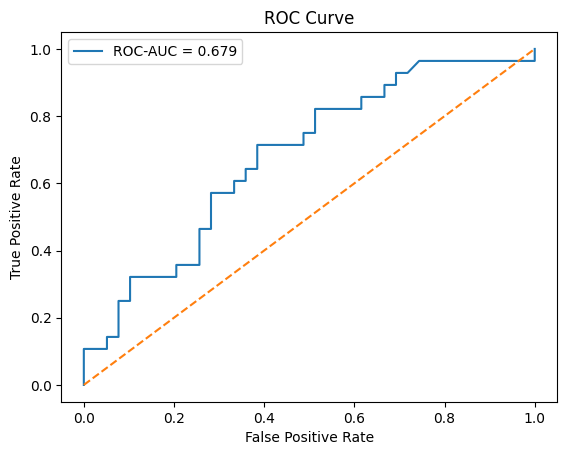

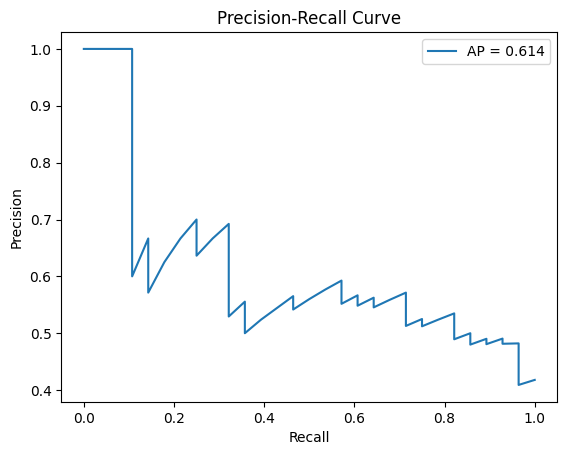

In [5]:
# HANCOCK GPT-2 CLASSIFIER
# ============================================================
# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
# ============================================================
import os, random, json, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

SEED = 42

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# 2. LOAD AND MERGE HANCOCK CLINICAL/PATHOLOGICAL DATA
# ============================================================
CLINICAL_FILE = "clinical_data.json"
PATHOLOGICAL_FILE = "pathological_data.json"

if not os.path.exists(CLINICAL_FILE):
    if gdown.download(
        id="1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q",
        output=CLINICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download clinical_data.json.")

if not os.path.exists(PATHOLOGICAL_FILE):
    if gdown.download(
        id="1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F",
        output=PATHOLOGICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download pathological_data.json.")

def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        try:
            return pd.DataFrame(obj)
        except ValueError:
            pass
    raise ValueError(f"Could not convert {path} to a table.")

clinical_df = load_json_table(CLINICAL_FILE)
pathological_df = load_json_table(PATHOLOGICAL_FILE)
if ("patient_id" not in clinical_df.columns or
        "patient_id" not in pathological_df.columns):
    raise KeyError("Both JSON files must contain 'patient_id'.")

df = clinical_df.merge(
    pathological_df, on="patient_id", how="left",
    suffixes=("", "_path")
)
print("Clinical shape:", clinical_df.shape)
print("Pathology shape:", pathological_df.shape)
print("Merged shape:", df.shape)

# ============================================================
# 3. SELECT SIX FEATURES AND DEFINE THE HPV TARGET
# ============================================================
def resolve_col(candidates, required=False):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(
            f"Required column not found: {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )
    return None

target_col = resolve_col(
    ["hpv_association_p16", "hpv_association_p16_path"],
    required=True
)
feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis", "age_at_initial_diagnosis_path"
    ],
    "sex": ["sex", "sex_path"],
    "smoking_status": ["smoking_status", "smoking_status_path"],
    "primary_tumor_site": [
        "primary_tumor_site", "primary_tumor_site_path"
    ],
    "primarily_metastasis": [
        "primarily_metastasis", "primarily_metastasis_path"
    ],
    "pN_stage": [
        "pN_stage", "pN_stage_path",
        "pathological_N_stage", "pathological_n_stage"
    ]
}
feature_map = {
    name: resolve_col(cols, required=True)
    for name, cols in feature_candidates.items()
}
features = list(feature_candidates.keys())
df = df.dropna(subset=[target_col]).copy()

def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in ["negative", "neg", "0", "false", "no"]:
        return 0
    if s in ["positive", "pos", "1", "true", "yes"]:
        return 1
    try:
        n = float(s)
        if n in [0, 1]:
            return int(n)
    except ValueError:
        pass
    return np.nan

df["HPV_Label"] = df[target_col].apply(normalize_target)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
feature_df = df[[feature_map[c] for c in features]].copy()
feature_df = feature_df.rename(
    columns={feature_map[c]: c for c in features}
)
df = pd.concat([feature_df, df[["HPV_Label"]]], axis=1)
df = df.loc[:, ~df.columns.duplicated()].copy()
df["age_at_initial_diagnosis"] = pd.to_numeric(
    df["age_at_initial_diagnosis"], errors="coerce"
)
print("Patients:", len(df))
print("HPV classes (0=negative, 1=positive):")
print(df["HPV_Label"].value_counts().sort_index())
print("Features:", features)
print("N-stage source:", feature_map["pN_stage"])

# ============================================================
# 4. STRATIFIED TRAIN/VALIDATION/TEST SPLIT (65/15/20)
# ============================================================
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED,
    stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = (
    split.copy() for split in [train_df, val_df, test_df]
)

# ============================================================
# 5. IMPUTE MISSING VALUES USING TRAINING DATA ONLY
# ============================================================
fill_values = {}
for c in features:
    if pd.api.types.is_numeric_dtype(train_df[c]):
        value = train_df[c].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[c].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[c] = value
    for split in [train_df, val_df, test_df]:
        split[c] = split[c].fillna(value)
        if split[c].dtype == object:
            split[c] = split[c].astype(str).replace({
                "": "Unknown", "nan": "Unknown", "None": "Unknown"
            })

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
print("Train:", len(train_df), np.bincount(y_train, minlength=2))
print("Validation:", len(val_df), np.bincount(y_val, minlength=2))
print("Test:", len(test_df), np.bincount(y_test, minlength=2))
# ============================================================
# 6. CONVERT EXACTLY SIX CLINICAL FEATURES INTO TEXT
# ============================================================

def display_value(x):
    if pd.isna(x):
        return "Unknown"

    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))

    return str(x).strip()


def patient_to_text(row):

    # Feature 1: Age
    age = display_value(row["age_at_initial_diagnosis"])

    # Feature 2: Sex
    sex_value = str(row["sex"]).strip().lower()

    if sex_value in ["1", "male", "m"]:
        sex = "male"
    elif sex_value in ["0", "female", "f"]:
        sex = "female"
    else:
        sex = display_value(row["sex"])

    # Feature 3: Smoking status
    smoking_value = str(row["smoking_status"]).strip().lower()

    if smoking_value in ["0", "non-smoker", "nonsmoker", "never"]:
        smoking = "a non-smoker"
    elif smoking_value in ["1", "smoker", "current smoker", "yes"]:
        smoking = "a smoker"
    else:
        smoking = display_value(row["smoking_status"])

    # Feature 4: Primary tumour site
    site = display_value(row["primary_tumor_site"])

    # Feature 5: Primarily metastasis
    metastasis = display_value(row["primarily_metastasis"])

    # Feature 6: Pathological N stage
    n_stage = display_value(row["pN_stage"])

    prompt = (
        "Q: Predict this patient's Human Papillomavirus (HPV) status "
        "using the clinical information available. "

        f"This patient is {age} years old and is {sex}. "
        f"The patient is {smoking}. "
        f"The primary tumour site is {site}. "
        f"The primarily metastasis status is {metastasis}. "
        f"Pathological nodal stage is {n_stage}. "

        "Based on these six clinical features, "
        "predict whether the patient is HPV positive or HPV negative. "
        "Answer with only Yes or No.\nA:"
    )

    return prompt


# Verify exactly six input features
features = [
    "age_at_initial_diagnosis",
    "sex",
    "smoking_status",
    "primary_tumor_site",
    "primarily_metastasis",
    "pN_stage"
]

assert len(features) == 6

print("Number of clinical features:", len(features))
print("Features:", features)

print("\nExample clinical prompt:")
print(patient_to_text(df.iloc[0]))


# ============================================================
# 7. LOAD FROZEN GPT-2 WITH CLASSIFICATION LAYER
# ============================================================

# Load tokenizer
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token

# Load GPT-2
gpt2 = GPT2Model.from_pretrained("gpt2")

# Freeze GPT-2 parameters
for param in gpt2.parameters():
    param.requires_grad = False

classifier = nn.Sequential(
    nn.Linear(768, 128),
    nn.ReLU(),
    nn.Linear(128, 2)
)

classifier = classifier.to(device)

# Move models to device
gpt2 = gpt2.to(device)
classifier = classifier.to(device)


# ============================================================
# 8. TOKENISE HANCOCK DATA
# ============================================================

# Convert each patient into text
train_texts = [patient_to_text(row) for _, row in train_df.iterrows()]
val_texts = [patient_to_text(row) for _, row in val_df.iterrows()]
test_texts = [patient_to_text(row) for _, row in test_df.iterrows()]

# Tokenise the text
train_inputs = tokenizer(
    train_texts,
    padding=True,
    truncation=True,
    return_tensors="pt"
)

val_inputs = tokenizer(
    val_texts,
    padding=True,
    truncation=True,
    return_tensors="pt"
)

test_inputs = tokenizer(
    test_texts,
    padding=True,
    truncation=True,
    return_tensors="pt"
)

print("Training inputs:", train_inputs["input_ids"].shape)
print("Validation inputs:", val_inputs["input_ids"].shape)
print("Test inputs:", test_inputs["input_ids"].shape)



# ============================================================
# 9. EXTRACT GPT-2 FEATURES
# ============================================================

gpt2.eval()

with torch.no_grad():

    train_outputs = gpt2(
        input_ids=train_inputs["input_ids"].to(device),
        attention_mask=train_inputs["attention_mask"].to(device)
    )

    val_outputs = gpt2(
        input_ids=val_inputs["input_ids"].to(device),
        attention_mask=val_inputs["attention_mask"].to(device)
    )

    test_outputs = gpt2(
        input_ids=test_inputs["input_ids"].to(device),
        attention_mask=test_inputs["attention_mask"].to(device)
    )

# Get the last non-padding token representation
def get_features(outputs, attention_mask):

    last_token_idx = attention_mask.sum(dim=1) - 1

    return outputs.last_hidden_state[
        torch.arange(outputs.last_hidden_state.size(0)),
        last_token_idx
    ]

train_features = get_features(
    train_outputs, train_inputs["attention_mask"]
)

val_features = get_features(
    val_outputs, val_inputs["attention_mask"]
)

test_features = get_features(
    test_outputs, test_inputs["attention_mask"]
)

print("Training features:", train_features.shape)
print("Validation features:", val_features.shape)
print("Test features:", test_features.shape)

# ============================================================
# 10. TRAIN CLASSIFIER
# ============================================================

# Convert labels to tensors
y_train_tensor = torch.tensor(y_train, dtype=torch.long).to(device)
y_val_tensor = torch.tensor(y_val, dtype=torch.long).to(device)


# Create batches of 64
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(train_features, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# Training
EPOCHS = 500

for epoch in range(EPOCHS):

    classifier.train()

    for batch_features, batch_labels in train_loader:

        optimizer.zero_grad()

        # Training predictions
        train_logits = classifier(batch_features)

        # Calculate loss
        loss = criterion(train_logits, batch_labels)

        # Update classifier
        loss.backward()
        optimizer.step()

    # Validation
    classifier.eval()

    with torch.no_grad():

        val_logits = classifier(val_features)

        val_predictions = torch.argmax(val_logits, dim=1)

        val_accuracy = (
            val_predictions == y_val_tensor
        ).float().mean()

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss: {loss.item():.4f} | "
        f"Validation Accuracy: {val_accuracy.item():.4f}"
    )

# ============================================================
# 11. TEST AND EVALUATE MODEL
# ============================================================

classifier.eval()

y_test_tensor = torch.tensor(y_test, dtype=torch.long).to(device)

with torch.no_grad():
    test_logits = classifier(test_features)
    test_probs = torch.softmax(test_logits, dim=1)[:, 1]
    test_predictions = torch.argmax(test_logits, dim=1)

# Balanced accuracy
balanced_acc = balanced_accuracy_score(
    y_test,
    test_predictions.cpu().numpy()
)

# ROC curve and AUC
fpr, tpr, _ = roc_curve(
    y_test,
    test_probs.cpu().numpy()
)

roc_auc = roc_auc_score(
    y_test,
    test_probs.cpu().numpy()
)

# Precision-Recall curve and Average Precision
precision, recall, _ = precision_recall_curve(
    y_test,
    test_probs.cpu().numpy()
)

pr_auc = average_precision_score(
    y_test,
    test_probs.cpu().numpy()
)

# Print results
print("Balanced Accuracy:", balanced_acc)
print("ROC-AUC:", roc_auc)
print("Average Precision:", pr_auc)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

# Plot Precision-Recall curve
plt.figure()
plt.plot(recall, precision, label=f"AP = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()
